# AP 155 Lab Exercise
---
## Exercise 12: Montecarlo Methods

_Instructions_:
- **Report Figures**: 
 1. initial spin configuration, you choose  $T$
 2. spin configuration after 10,000 sweeps, for $T$ above and below $T_C$
 3. magnetization and energy, for $T$ above and below $T_C$
 4. magnetization and energy with external field, for $T$ above and below $T_C$
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Refuerzo, Paul Adam
- _Student No._: 2024-09465
- _Section_: WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure
![1](finallattice.png)
**Figure 1.** Final 2D Ising Lattices Under Different Magnetic Fields and Temperatures
![1](energyLec12.png)
**Figure 2.** Energy per Spin Under Different Magnetic Fields and Temperatures
![1](magnetLec12.png)
**Figure 3.** Magnetization per Spin Under Different Magnetic Fields and Temperatures

### Report discussion

Figure 1 displays the final spin configurations after $10{,}000$ sweeps across different temperatures and external magnetic fields. Below the critical temperature ($T = 1.0 < T_C \approx 2.269$), the spins lock into a single uniform domain, settling entirely into spin-down when $B = 0$ and fully aligning into spin-up when $B = 0.5$. Above the critical temperature ($T = 3.0 > T_C$), long-range order disappears, leaving the lattice fragmented into small clusters with roughly balanced spins at $B = 0$ and a slight spin-up bias at $B = 0.5$.

Figure 2 shows the evolution of energy per spin over $10{,}000$ Monte Carlo sweeps for all four parameter combinations. At $T = 1.0$, the energy drops sharply during the first few hundred sweeps to the ground-state minimum, plateauing at $E/N^2 = -2.0$ for $B = 0$ and lowering further to $E/N^2 = -2.5$ for $B = 0.5$. Conversely, at $T = 3.0$, continuous spin flips keep the system in a higher-energy disordered state, fluctuating around $E/N^2 \approx -0.85$ for $B = 0$ and around $E/N^2 \approx -1.75$ when $B = 0.5$ is applied.

Figure 3 shows the corresponding magnetization per spin trajectories throughout the simulation. At $T = 1.0$, the system rapidly saturates at $m = 1.0$ for both $B$ values. At $T = 3.0$, spontaneous magnetization vanishes when $B = 0$ as $m$ oscillates randomly around zero, while introducing $B = 0.5$ shifts the magnetization per spin to fluctuate around $m \approx +0.8$.

### Other comments

Figure 1 plot for B = 0, T = 3 looks like a dinosaur.

---
## Section 2: Code

# Exercise: The Two-Dimensional Ising Model

## Introduction

The Ising model describes the magnetic behavior of a material using interacting spins arranged on a lattice. Each spin can take one of two values, $S_{i,j}=\pm1$, representing spin-up and spin-down orientations.

In this exercise, you will simulate a two-dimensional Ising model using the **Metropolis Monte Carlo algorithm**. You will investigate how spin interactions, temperature, and external magnetic fields affect the system's energy and magnetization.

## 1. Setting Up the Ising Model

Consider a square lattice of size $N\times N$. Each spin interacts with its four nearest neighbors.

The energy of the system is given by the Ising Hamiltonian:

$$
H(\mathbf S)=-J\sum_{\langle ij\rangle}S_iS_j
$$

where $J$ is the interaction strength and the summation includes each unique neighboring pair exactly once.

Use **periodic boundary conditions**, where the lattice wraps around itself so that every spin has four neighbors.

**Tasks:**

1. Create a $20\times20$ lattice with randomly initialized spins of $+1$ or $-1$.
2. Plot the initial spin configuration.
3. Write a function to calculate the total energy using:

$$
H=-J\sum_{i,j}S_{i,j}(S_{i+1,j}+S_{i,j+1})
$$

**Guide questions:**
- What is the expected initial magnetization?
- What is the energy of a completely aligned lattice when $J>0$?

## 2. Implementing the Metropolis Algorithm

The probability of a spin configuration is proportional to its Boltzmann factor:

$$
w(\mathbf S)\propto e^{-H(\mathbf S)/(k_BT)}
$$

To simulate the system, randomly select and attempt to flip one spin at a time.

For each attempted flip:

1. Randomly select a spin $S_{i,j}$.
2. Flip its orientation: $S_{i,j}'=-S_{i,j}$.
3. Calculate the energy change:

$$
\Delta H=H_{\text{new}}-H_{\text{old}}
$$

4. Accept the flip with probability:

$$
P_{\text{accept}}=\min\left(1,e^{-\Delta H/(k_BT)}\right)
$$

Let $J = T = k_B = 1$. Test your simulation for 10,000 Monte Carlo sweeps. Note that one sweep will cover $N^2$ lattice sites.

## 3. Investigating Spontaneous Magnetization

The total magnetization measures the overall alignment of spins:

$$
M=\sum_{i,j}S_{i,j}
$$

Define the (average) magnetization per spin as:

$$
m=\frac{M}{N^2}
$$

Its value ranges from $-1$ to $+1$, with values near zero indicating an approximately balanced spin distribution.

**Tasks:**

1. Run the simulation for $10^4 - 10^6$ attempted spin flips, you decide what's appropriate.
2. Record the magnetization per spin and total energy throughout the simulation.
3. Plot magnetization per spin and total energy against Monte Carlo sweeps.
4. Repeat the simulation using different random initial configurations.

**Guide questions:**
- Does the system develop spontaneous magnetization?
- Why can separate simulations produce positive or negative magnetization?
- What determines the preferred spin orientation?

## 4. Introducing an External Magnetic Field

Modify the Hamiltonian to include a uniform external magnetic field:

$$
H(\mathbf S)=-J\sum_{\langle ij\rangle}S_iS_j-B\sum_{i,j}S_{i,j}
$$

For a single spin flip, the energy change becomes:

$$
\boxed{
\Delta H=2S_{i,j}
\left[
J(S_{i+1,j}+S_{i-1,j}+S_{i,j+1}+S_{i,j-1})+B
\right]
}
$$

**Tasks:**

Modify your simulation using $B=0.5$

1. Update the energy calculation and Metropolis algorithm.
2. Run the simulation and record energy and magnetization per spin.
3. Plot magnetization per spin against Monte Carlo sweeps.

**Guide questions:**
- How does the external magnetic field affect spin alignment?
- Why does the system favor one magnetization direction over the other?

## 5. Critical Temperature

The critical temperature of the 2D Ising model is 

$$T_C \approx 2.269 \frac{J}{k_B}$$

**Task:**

Previously you let $T=1$, which is below this critical temperature  for $J=1=k_B$. Redo Sections 2, 3, and 4 by selecting a temperature **above** $T_C$.

In [50]:
import numpy as np
import matplotlib.pyplot as plt
import math
rng = np.random.default_rng(202409465)

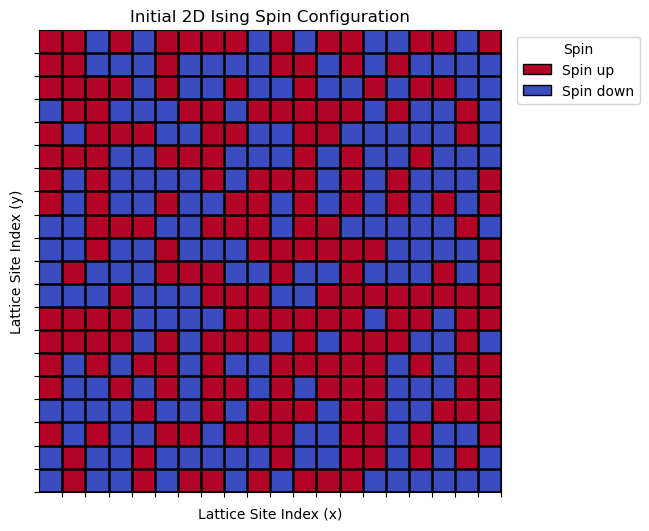

In [51]:
N = 20
J = 1.0
B = 0.5
K_B = 1.0

lattice = rng.choice([1, -1], size=(N, N))

plt.figure(figsize=(6, 6))

plt.imshow(lattice, cmap='coolwarm', origin='upper')
plt.title('Initial 2D Ising Spin Configuration')
plt.xlabel('Lattice Site Index (x)')
plt.ylabel('Lattice Site Index (y)')

cmap = plt.cm.coolwarm
legend_elements = [
    plt.Rectangle((0, 0), 1, 1, facecolor=cmap(1.0), edgecolor='black', label='Spin up'),
    plt.Rectangle((0, 0), 1, 1, facecolor=cmap(0.0), edgecolor='black', label='Spin down')
]
plt.legend(handles=legend_elements, title='Spin', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.gca().set_xticks(np.arange(0.5, N, 1))
plt.gca().set_yticks(np.arange(0.5, N, 1))
plt.gca().axes.xaxis.set_ticklabels([])
plt.gca().axes.yaxis.set_ticklabels([])
plt.grid(color='black', linewidth='1.8')

plt.show()

In [52]:
def hamiltonian(lattice):
    down = np.roll(lattice, -1, axis=0)
    right = np.roll(lattice, -1, axis=1)
    return - J * np.sum(lattice * (down + right))

H_old = hamiltonian(lattice); mH_old = H_old - B * np.sum(lattice)

i = rng.integers(low=0, high=N)
j = rng.integers(low=0, high=N)
lattice_new = lattice.copy() ; lattice_new[i][j] *= -1

H_new = hamiltonian(lattice_new); mH_new = H_new - B * np.sum(lattice_new)
dH, dmH = H_new - H_old, mH_new - mH_old

print(H_old, mH_old)
print(H_new, mH_new)
print(dH, dmH)

4.0 1.0
4.0 0.0
0.0 -1.0


In [53]:
def metropolis(lattice, B, T, n_sweeps=10000):
    S = lattice.copy()
    M = int(np.sum(S))
    E = hamiltonian(S) - (B * M)

    energies = np.empty(n_sweeps + 1)
    mags = np.empty(n_sweeps + 1)
    energies[0], mags[0] = E, M

    for sweep in range(n_sweeps):
        sites = rng.integers(0, N, size=(N**2, 2))
        rands = rng.random(N**2)

        for (i, j), r in zip(sites, rands):
            neighbors = (
                S[(i + 1) % N, j]
                + S[(i - 1) % N, j]
                + S[i, (j + 1) % N]
                + S[i, (j - 1) % N]
            )
            dH = 2 * J * S[i, j] * neighbors + (2 * B * S[i, j])

            if dH <= 0 or r < np.exp(-dH / (K_B * T)):
                M += -2 * S[i, j]
                E += dH
                S[i, j] *= -1

        energies[sweep + 1] = E
        mags[sweep + 1] = M

    return S, energies, mags

final_lattice, energies, magnetization = metropolis(lattice, 0, 1, n_sweeps=10000)
final_latwB, enerwB, magnetwB = metropolis(lattice, 0.5, 1, n_sweeps=10000)
final_lattice3, energies3, magnetization3 = metropolis(lattice, 0, 3, n_sweeps=10000)
final_latwB3, enerwB3, magnetwB3 = metropolis(lattice, 0.5, 3, n_sweeps=10000)

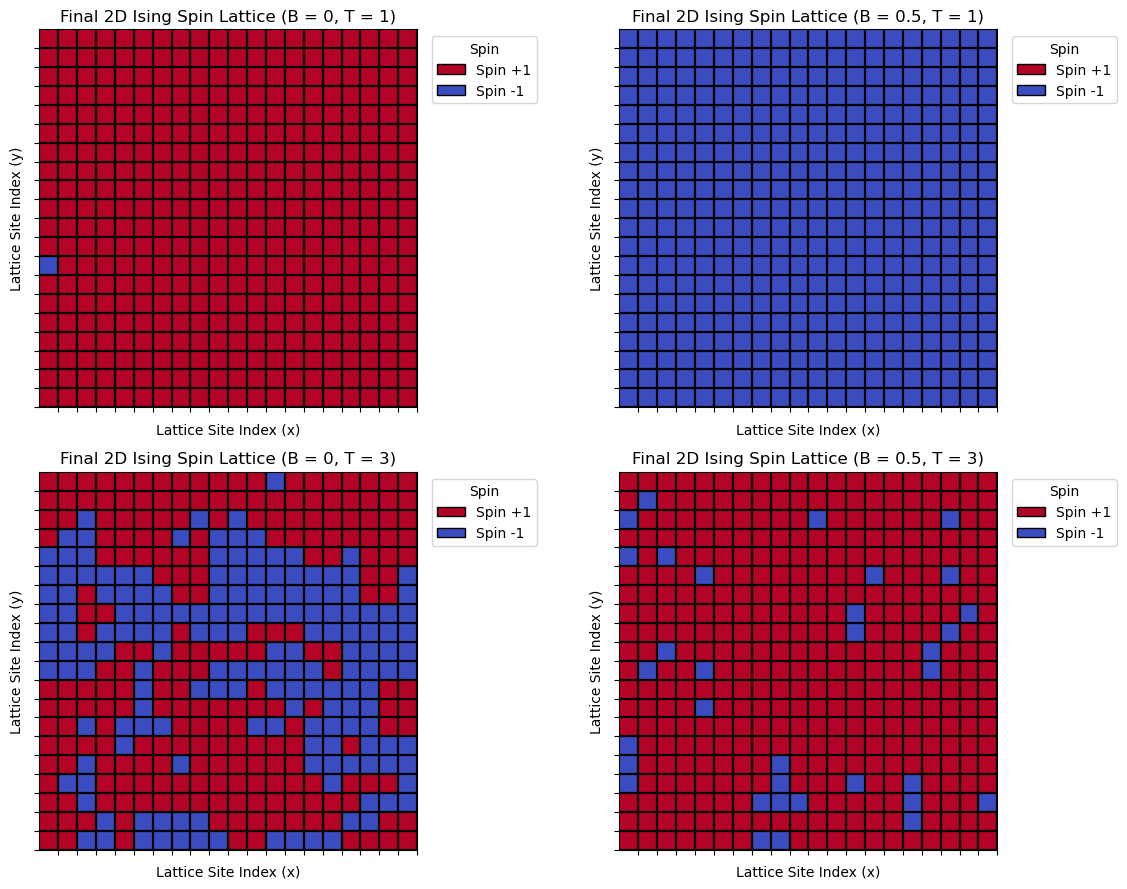

In [54]:
fig, axs = plt.subplots(2, 2, figsize=(12, 9))

axs[0,0].imshow(final_lattice, cmap='coolwarm', origin='upper')
axs[0,0].set_title('Final 2D Ising Spin Lattice (B = 0, T = 1)')
axs[0,0].set_xlabel('Lattice Site Index (x)')
axs[0,0].set_ylabel('Lattice Site Index (y)')

axs[0,0].set_xticks(np.arange(0.5, N, 1))
axs[0,0].set_yticks(np.arange(0.5, N, 1))
axs[0,0].set_xticklabels([])
axs[0,0].set_yticklabels([])
axs[0,0].grid(color='black', linewidth=1.6)

cmap = plt.cm.coolwarm
legend_elements = [
    plt.Rectangle((0, 0), 1, 1, facecolor=cmap(1.0), edgecolor='black', label='Spin +1'),
    plt.Rectangle((0, 0), 1, 1, facecolor=cmap(0.0), edgecolor='black', label='Spin -1')
]
axs[0,0].legend(handles=legend_elements, title='Spin', bbox_to_anchor=(1.02, 1), loc='upper left')

axs[0,1].imshow(final_latwB, cmap='coolwarm', origin='upper')
axs[0,1].set_title('Final 2D Ising Spin Lattice (B = 0.5, T = 1)')
axs[0,1].set_xlabel('Lattice Site Index (x)')
axs[0,1].set_ylabel('Lattice Site Index (y)')

axs[0,1].set_xticks(np.arange(0.5, N, 1))
axs[0,1].set_yticks(np.arange(0.5, N, 1))
axs[0,1].set_xticklabels([])
axs[0,1].set_yticklabels([])
axs[0,1].grid(color='black', linewidth=1.6)

cmap = plt.cm.coolwarm
legend_elements = [
    plt.Rectangle((0, 0), 1, 1, facecolor=cmap(1.0), edgecolor='black', label='Spin +1'),
    plt.Rectangle((0, 0), 1, 1, facecolor=cmap(0.0), edgecolor='black', label='Spin -1')
]
axs[0,1].legend(handles=legend_elements, title='Spin', bbox_to_anchor=(1.02, 1), loc='upper left')

axs[1,0].imshow(final_lattice3, cmap='coolwarm', origin='upper')
axs[1,0].set_title('Final 2D Ising Spin Lattice (B = 0, T = 3)')
axs[1,0].set_xlabel('Lattice Site Index (x)')
axs[1,0].set_ylabel('Lattice Site Index (y)')

axs[1,0].set_xticks(np.arange(0.5, N, 1))
axs[1,0].set_yticks(np.arange(0.5, N, 1))
axs[1,0].set_xticklabels([])
axs[1,0].set_yticklabels([])
axs[1,0].grid(color='black', linewidth=1.6)

cmap = plt.cm.coolwarm
legend_elements = [
    plt.Rectangle((0, 0), 1, 1, facecolor=cmap(1.0), edgecolor='black', label='Spin +1'),
    plt.Rectangle((0, 0), 1, 1, facecolor=cmap(0.0), edgecolor='black', label='Spin -1')
]
axs[1,0].legend(handles=legend_elements, title='Spin', bbox_to_anchor=(1.02, 1), loc='upper left')

axs[1,1].imshow(final_latwB3, cmap='coolwarm', origin='upper')
axs[1,1].set_title('Final 2D Ising Spin Lattice (B = 0.5, T = 3)')
axs[1,1].set_xlabel('Lattice Site Index (x)')
axs[1,1].set_ylabel('Lattice Site Index (y)')

axs[1,1].set_xticks(np.arange(0.5, N, 1))
axs[1,1].set_yticks(np.arange(0.5, N, 1))
axs[1,1].set_xticklabels([])
axs[1,1].set_yticklabels([])
axs[1,1].grid(color='black', linewidth=1.6)

cmap = plt.cm.coolwarm
legend_elements = [
    plt.Rectangle((0, 0), 1, 1, facecolor=cmap(1.0), edgecolor='black', label='Spin +1'),
    plt.Rectangle((0, 0), 1, 1, facecolor=cmap(0.0), edgecolor='black', label='Spin -1')
]
axs[1,1].legend(handles=legend_elements, title='Spin', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.savefig('finallattice', dpi=300)
plt.show()

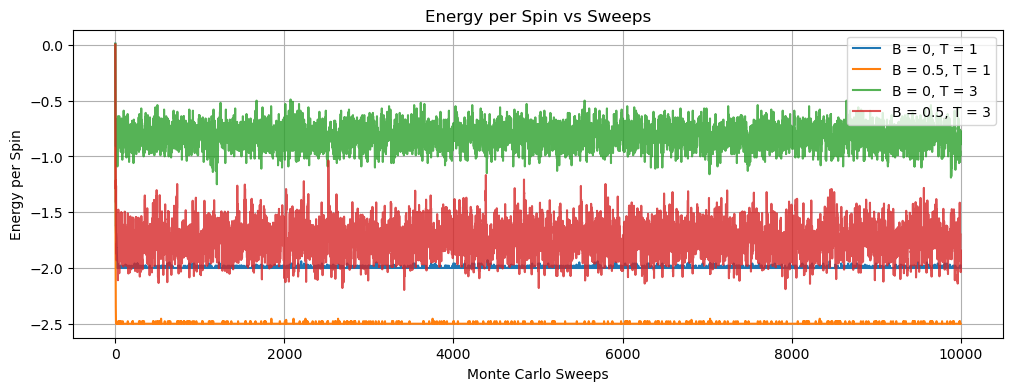

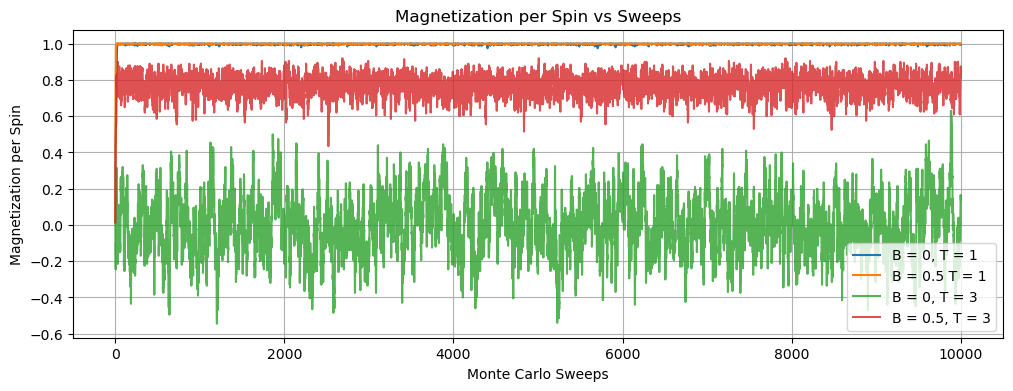

In [55]:
plt.figure(figsize=(12, 4))
plt.plot(energies / N**2, label='B = 0, T = 1')
plt.plot(enerwB / N**2, label='B = 0.5, T = 1')
plt.plot(energies3 / N**2, label='B = 0, T = 3', alpha=0.8)
plt.plot(enerwB3 / N**2, label='B = 0.5, T = 3', alpha=0.8)
plt.title('Energy per Spin vs Sweeps')
plt.xlabel('Monte Carlo Sweeps')
plt.ylabel('Energy per Spin')
plt.legend()
plt.grid()
plt.savefig('energyLec12', dpi=300)
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(magnetization / N**2, label='B = 0, T = 1')
plt.plot(magnetwB / N**2, label='B = 0.5 T = 1')
plt.plot(magnetization3 / N**2, label='B = 0, T = 3', alpha=0.8)
plt.plot(magnetwB3 / N**2, label='B = 0.5, T = 3', alpha=0.8)
plt.title('Magnetization per Spin vs Sweeps')
plt.xlabel('Monte Carlo Sweeps')
plt.ylabel('Magnetization per Spin')
plt.legend()
plt.grid()
plt.savefig('magnetLec12', dpi=300)
plt.show()

#### Problem code summary

The code above generates a 20 by 20 lattice of spins ups and downs by first making a 2d array with random values -1 and 1, then plotting it using plt.imshow. This initial lattice is then used for the metropolis algorithm for the cases with and without a mmagnetic field, and with lower and higher T than the critical temperature. This is easily done by including the parameter B and T in the inputs of the function metropolis.